# MNIST Handwritten Digit Classifier

This notebook trains a neural network to classify grayscale images of handwritten digits from **0 to 9**. Each 28 × 28 image is flattened into 784 pixel values for the model.

The network has two hidden layers with 128 neurons each, followed by dropout to help reduce overfitting. Its 10-neuron Softmax output gives a probability for each digit; the highest probability is the prediction.

Finally, the model is evaluated on test images. A confusion matrix summarizes its predictions, and selected misclassified images help show which digits it finds difficult to recognize.

You have also the Option to upload your own images and test them after training the network.

Imports:

In [ ]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from sklearn.metrics import confusion_matrix
import seaborn as sns

np.random.seed(0)

Data:

In [2]:
from keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [3]:
print("Training data shape:", x_train.shape, y_train.shape)
print("Testing data shape:", x_test.shape, y_test.shape)

Training data shape: (60000, 28, 28) (60000,)
Testing data shape: (10000, 28, 28) (10000,)


Visialize Examples:

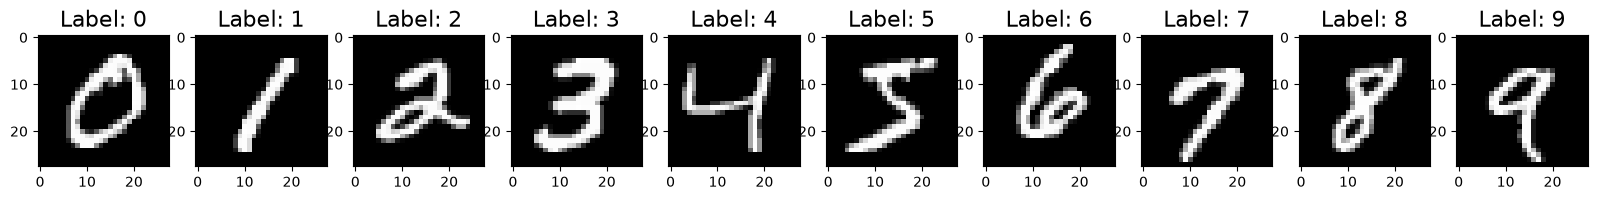

In [4]:
num_classes = 10 #cases we have
f, ax = plt.subplots(1, num_classes, figsize=(20, 20)) # for figure, ax for axes
for i in range(num_classes):
    sample = x_train[y_train == i][0] # get the first sample of each class
    ax[i].imshow(sample, cmap='gray') # display the image in grayscale
    ax[i].set_title("Label: {}".format(i), fontsize=16)

In [5]:
for i in range(10):
    print(y_train[i])
# to display the first 10 labels of the training data

5
0
4
1
9
2
1
3
1
4


In [6]:
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)
""" 
means:
take each integer label in y_train, turn it into a vector of length num_classes
set the correct index to 1 and the rest to 0 so if y_train looks initially like this:
[5, 0, 4, 1, 9, 2, 1, 3, 1, 4]
after one-hot encoding it will look like this: class 5 -> [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
class 0 -> [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]"""

' \nmeans:\ntake each integer label in y_train, turn it into a vector of length num_classes\nset the correct index to 1 and the rest to 0 so if y_train looks initially like this:\n[5, 0, 4, 1, 9, 2, 1, 3, 1, 4]\nafter one-hot encoding it will look like this: class 5 -> [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]\nclass 0 -> [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]'

In [7]:
for i in range(10):
    print(y_train[i])
# this will display the first 10 labels of the training data after one-hot encoding. so if the label is
#  [0, 0, 0, 0, 0, 0, 0, 1, 0, 0] this means the first image is of digit 7.

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


Prepare Data:
we need to normalize our Data. out data is of images and they are between 0 and 255 so to normalize it we will devide each one by 255

In [8]:
#normalize the data
x_train = x_train / 255.0
x_test = x_test / 255.0

In [9]:
#now reshape it to be a 1D array of 784 pixels instead of a 28x28 array
x_train = x_train.reshape(x_train.shape[0], -1 )
x_test = x_test.reshape(x_test.shape[0], -1 )
# so the original shape of x_train was (60000, 28, 28) and now it is (60000, 784)
print ("Training data shape after reshaping:", x_train.shape)


Training data shape after reshaping: (60000, 784)


Create Model - Fully Connected Neural Network

In [10]:
# each MNIST image has been flattened to 784 pixel values. now we use keras sequential model
model = Sequential()

model.add(Dense(units = 128, input_shape = (784, ), activation='relu' )) 
"""the first fully connected (dense) layer:
It takes 784 input values—the pixels of one flattened 28×28 image.
It has 128 neurons (units=128).
relu is the activation function; it helps the network learn non-linear patterns."""

model.add(Dense(units = 128, activation='relu' )) 
"""Adds a second dense layer with 128 neurons. Keras infers its input 
size from the previous layer’s 128 outputs, so you don’t need to specify 
input_shape again. It is 784, not 748, in the first layer."""

model.add(Dropout(0.25)) 
#During training, randomly sets 25% of the layer’s outputs to zero. 
# This can help reduce overfitting. Dropout is turned off during evaluation and prediction.

model.add(Dense(units=10, activation='softmax')) 
"""Adds the output layer:
10 neurons represent the ten possible digits: 0 through 9.
softmax turns the outputs into probabilities that add up to 1.
 The highest probability is the model’s predicted digit."""

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
"""Configures how the model will train:
Loss measures how far predictions are from the correct labels.
Adam is the method used to update the model’s weights during training.
Accuracy is reported as a metric."""

model.summary()


keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

Now we Train:

In [11]:
batch_size = 512
epochs = 10

model.fit(x=x_train, y=y_train, batch_size=batch_size, epochs = epochs)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8224 - loss: 0.6052
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9331 - loss: 0.2277
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9499 - loss: 0.1680
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9617 - loss: 0.1342
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9677 - loss: 0.1107
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9724 - loss: 0.0942
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9757 - loss: 0.0809
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9786 - loss: 0.0728
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9797 - loss: 0.0646
Epoch 10/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9831 - loss: 0.0566


Evaluate:

In [12]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
# now after the model is trained we will evaluate it with data that it has 
# yet not seen
print("Test Loss: {}, Test Accuracy:{}".format(test_loss, test_accuracy))

 22/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9773 - loss: 0.0721

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9753 - loss: 0.0751
Test Loss: 0.07506974786520004, Test Accuracy:0.9753000140190125


In [13]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis= 1)
print(y_pred)
print(y_pred_classes)
# so the 7th element is the highest prob then the 2 etc.

  1/313 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
[[1.2314802e-06 6.4782029e-07 2.3690149e-05 ... 9.9991262e-01
  5.4552714e-07 7.8095818e-06]
 [1.4818073e-05 8.6312604e-05 9.9984014e-01 ... 6.2415459e-09
  9.7978582e-06 6.6491174e-11]
 [2.2001896e-05 9.9777514e-01 2.5610605e-04 ... 1.0268597e-03
  2.8595093e-04 3.2753072e-05]
 ...
 [4.8574383e-10 1.5760722e-07 1.6202836e-10 ... 2.2390964e-06
  8.3125343e-08 1.9094568e-05]
 [2.4186786e-08 6.1347123e-09 4.0933975e-11 ... 5.2136798e-08
  5.3982847e-05 5.4430522e-09]
 [2.5015174e-07 1.0287371e-10 4.6390798e-09 ... 4.7303784e-13
  1.2342261e-09 2.8967551e-10]]
[7 2 1 ... 4 5 6]


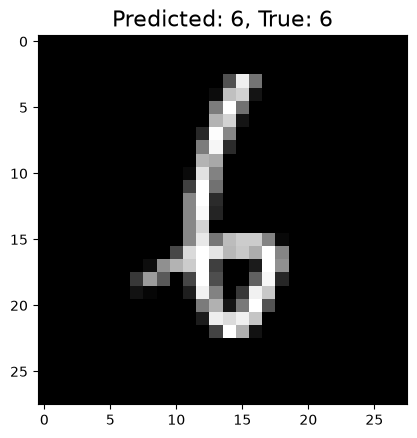

In [14]:
#Single Example
random_idx = np.random.choice(len(x_test))
# Chooses a random index from the test set. If x_test contains 10,000 images, 
# this selects a number from 0 to 9,999.

x_sample = x_test[random_idx]
# Gets the image at that index. If the images were flattened earlier, x_sample contains 784 pixel values.

y_true = np.argmax(y_test, axis=1)
"""If y_test contains one-hot labels, this converts each label back to a digit. For example, 
[0, 0, 1, 0, ...] becomes 2. axis=1 finds the position of the 1 in each row."""

y_sample_true = y_true[random_idx] # Gets the actual digit for the selected image.
y_sample_pred_class = y_pred_classes[random_idx]
"""Gets the model’s predicted digit for that image. 
This assumes y_pred_classes already contains class numbers from 0 to 9."""

plt.title("Predicted: {}, True: {}".format(y_sample_pred_class, y_sample_true), fontsize= 16)
plt.imshow(x_sample.reshape(28,28), cmap='grey')
# Reshapes the 784 pixels back into a 28×28 image and displays it in grayscale. 
# "gray" is the standard Matplotlib colormap name.


Confusion Matrix:

Text(0.5, 1.0, 'Confusion Matrix: ')

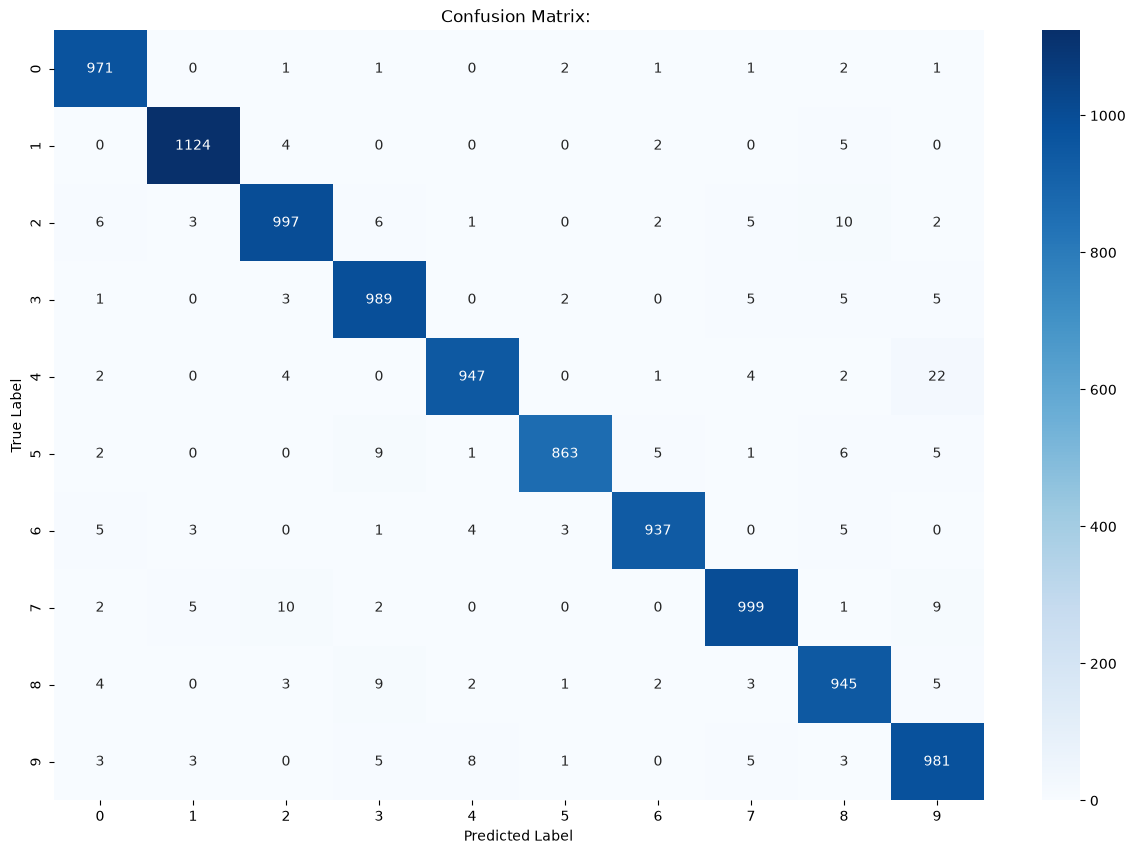

In [15]:
"""This code builds and plots a confusion matrix to show how well the model classified the test images."""
confusion_mtx = confusion_matrix(y_true, y_pred_classes)
"""Creates a table comparing the actual labels (y_true) with the model’s predicted labels 
(y_pred_classes). For MNIST, the rows and columns represent digits 0–9:
Rows are the true digits.
Columns are the predicted digits.
Values count how many images fall into each true/predicted pair."""

# Plot
fig, ax = plt.subplots(figsize=(15,10))
# Creates a figure and an axes area for the plot. figsize is measured in inches;
#  this makes the plot 15 inches wide and 10 inches tall.

ax = sns.heatmap(confusion_mtx, annot=True, ax=ax, fmt='d' , cmap ='Blues')
"""Draws the confusion matrix as a colored grid:
annot=True writes each count inside its cell.
ax=ax draws the heatmap on the axes created above.
fmt="d" displays values as whole numbers.
cmap="Blues" uses shades of blue; darker cells indicate larger counts."""

ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
ax.set_title('Confusion Matrix: ')

Investigate Some Errors:
We want to know what images got mislabled and visualize the reason

In [16]:
errors = (y_pred_classes - y_true != 0) # this is a boolean array
# this subtracts the predicted and true lables to find if they are different

y_pred_classes_errors = y_pred_classes[errors] 
# The predicted digit for each misclassified image.

y_pred_errors = y_pred[errors]
# The model’s full output for each misclassified image—usually its
#  probability for each digit (10 values per image).
y_true_errors = y_true[errors] # The correct digit for each misclassified image.
x_test_errors = x_test[errors]
# The test images the model got wrong. These are useful for displaying and inspecting its mistakes.

In [17]:
y_pred_errors_probability = np.max(y_pred_errors, axis = 1)
"""This code ranks the misclassified images by how much more confident the model was 
in its predicted digit than in the correct digit.
For each misclassified image, gets the model’s highest class probability—the confidence
 of its predicted digit. axis=1 means “find the maximum across the 10 digit probabilities in each row.”
"""
true_probability_errors = np.diagonal(np.take(y_pred_errors, y_true_errors, axis= 1))
"""Gets the probability the model assigned to the correct digit for each image.
y_pred_errors has one row per misclassified image and one column per digit.
np.take(..., axis=1) selects columns using the correct labels in y_true_errors.
np.diagonal(...) keeps the matching image/label pairs.
For example, if an image’s true digit is 4, this gets that image’s probability for digit 4."""

diff_errors_pred_true = y_pred_errors_probability - true_probability_errors
"""Calculates the gap between the probability of the model’s most likely digit and the
 probability of the correct digit. A larger gap means the model favored its wrong answer more strongly."""

# Get list of indices of sorted differences 
sorted_idx_diff_errors = np.argsort(diff_errors_pred_true)
# Returns the indices that would sort those gaps from smallest to largest. 
# It returns indices, not the probability values themselves.

top_idx_diff_errors = sorted_idx_diff_errors[-20:] # last 20 ones

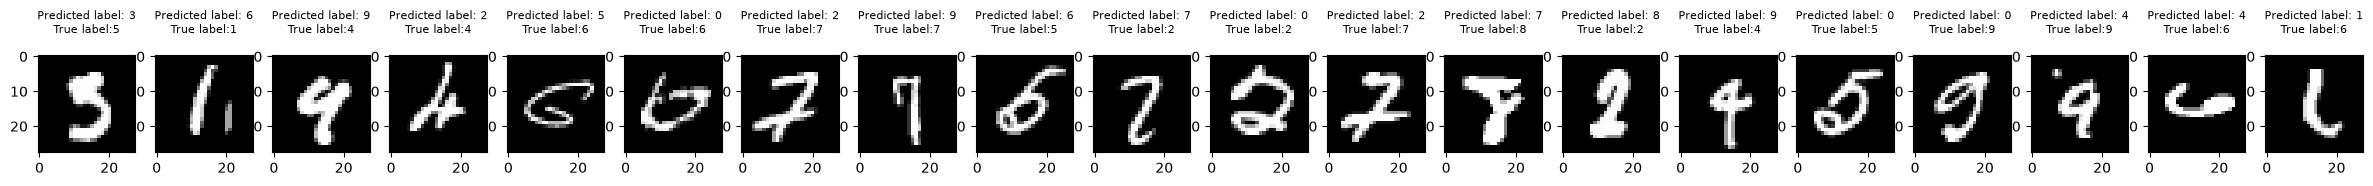

In [18]:
num = len(top_idx_diff_errors) # number of photos to be shown
f, ax = plt.subplots(1, num, figsize=(30,30)) # figures, axes

for i in range(0, num):
    idx = top_idx_diff_errors[i]
    sample = x_test_errors[idx].reshape(28,28)
    y_t = y_true_errors[idx] # y true
    y_p = y_pred_classes_errors[idx] # y predicted
    ax[i].imshow(sample, cmap = 'grey') # Displays the image in the ith plotting area, using grayscale.
    ax[i].set_title("Predicted label: {}\nTrue label:{}\n".format(y_p, y_t), fontsize =8)

## Try Your Own Digit Image

Run the code cell below after training the model to choose an image file from your computer. Use an image with one clearly visible handwritten digit (0-9). The code converts it to grayscale, scales and centers it on a 28 x 28 black canvas, then shows the model's predicted digit and confidence. Keep the notebook kernel running so the trained model remains available.

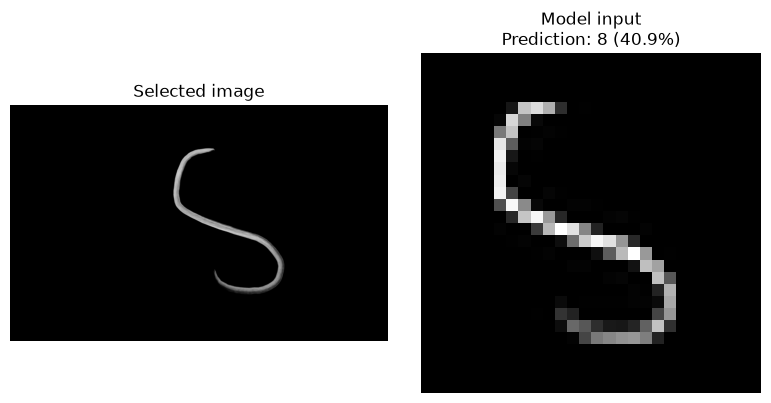

Predicted digit: 8 (confidence: 40.9%)


In [24]:
from tkinter import Tk, filedialog
from PIL import Image, ImageOps

def prepare_uploaded_digit(image_path):
    with Image.open(image_path) as uploaded:
        original = uploaded.convert("RGB")
        grayscale = ImageOps.autocontrast(uploaded.convert("L"))

    pixels = np.asarray(grayscale)
    border_pixels = np.concatenate((pixels[0, :], pixels[-1, :], pixels[:, 0], pixels[:, -1]))

    # MNIST uses a dark background and a light digit; invert light-background photos.
    if np.median(border_pixels) > 127:
        pixels = 255 - pixels

    threshold = max(20, int(pixels.max() * 0.15))
    rows, columns = np.where(pixels > threshold)
    if columns.size == 0:
        raise ValueError("No digit-like strokes were found in the selected image.")

    digit = Image.fromarray(pixels).crop(
        (columns.min(), rows.min(), columns.max() + 1, rows.max() + 1)
    )
    digit.thumbnail((20, 20), Image.Resampling.LANCZOS)

    model_input_image = Image.new("L", (28, 28), color=0)
    position = ((28 - digit.width) // 2, (28 - digit.height) // 2)
    model_input_image.paste(digit, position)

    model_input = np.asarray(model_input_image, dtype=np.float32).reshape(1, 784) / 255.0
    return model_input, original, model_input_image

root = Tk()
root.withdraw()
root.attributes("-topmost", True)
try:
    image_path = filedialog.askopenfilename(
        title="Choose a handwritten digit image",
        filetypes=[("Image files", "*.png *.jpg *.jpeg *.bmp *.tif *.tiff"), ("All files", "*.*")],
    )
finally:
    root.destroy()

if not image_path:
    print("No image selected.")
else:
    custom_image, original_image, model_input_image = prepare_uploaded_digit(image_path)
    probabilities = model.predict(custom_image, verbose=0)[0]
    predicted_digit = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_digit])

    figure, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(original_image)
    axes[0].set_title("Selected image")
    axes[1].imshow(model_input_image, cmap="gray")
    axes[1].set_title(f"Model input\nPrediction: {predicted_digit} ({confidence:.1%})")
    for axis in axes:
        axis.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"Predicted digit: {predicted_digit} (confidence: {confidence:.1%})")